# Paso 5 · Realimentación: $L$, $T$ y $S$ (con Python)

Notebook del **Paso 5**: del lazo abierto $L=GP$ al lazo cerrado $T=\frac{L}{1+L}$ y $S=\frac1{1+L}$, con la geometría de la flecha $1+L$.

| Concepto matemático | Concepto de programación |
|---|---|
| $L=GP$, $T$, $S$, $T+S=1$ | funciones de orden superior, `assert` de identidades |
| $1+L$ como flecha de $-1$ a $L$ | números complejos, `np.abs`, `np.angle` |
| tres regímenes de frecuencia | clasificación por umbral con `np.where` |
| Nyquist de $L(j\omega)$ | gráficos en el plano complejo |
| pico de $|T|$ | `np.argmax` sobre un barrido |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

AZUL, NARANJA, TINTA, GRIS = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e2de", "axes.axisbelow": True,
                     "font.size": 10})
np.set_printoptions(precision=4, suppress=True)

In [2]:
db = lambda z: 20 * np.log10(np.abs(z))
ang = lambda z: np.degrees(np.angle(z))

## 1. De $L$ al lazo cerrado en tres líneas

Con $L=GP$: $\;T=\dfrac{L}{1+L}$ (referencia→salida), $\;S=\dfrac{1}{1+L}$ (perturbación en la salida→salida) y **siempre** $T+S=1$.

In [3]:
T_de = lambda L: L / (1 + L)
S_de = lambda L: 1 / (1 + L)

L = 2 * np.exp(-1j * np.radians(120))        # el ejemplo a mano: L = 2∠-120°
print(f"L      = {abs(L):.3f}∠{ang(L):.1f}°  = {L:.4f}")
print(f"1 + L  = {abs(1+L):.4f}∠{ang(1+L):.2f}°  (esperado 1.73 de módulo)")
print(f"|T|    = {abs(T_de(L)):.4f} = {db(T_de(L)):.2f} dB ,  ∠T = {ang(T_de(L)):.2f}°")
print(f"|S|    = {abs(S_de(L)):.4f} = {db(S_de(L)):.2f} dB")
assert np.isclose(T_de(L) + S_de(L), 1)

L      = 2.000∠-120.0°  = -1.0000-1.7321j
1 + L  = 1.7321∠-90.00°  (esperado 1.73 de módulo)
|T|    = 1.1547 = 1.25 dB ,  ∠T = -30.00°
|S|    = 0.5774 = -4.77 dB


## 2. $1+L$ es la flecha que va de $-1$ a $L$

$|1+L|$ es la **distancia** del punto $L$ al punto crítico $-1$. Si está cerca, $|T|$ y $|S|$ **crecen**.

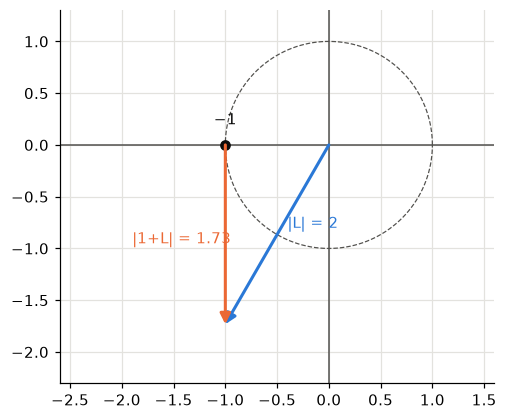

In [4]:
fig, ax = plt.subplots(figsize=(5.6, 4.4)); ax.set_aspect("equal")
th = np.linspace(0, 2*np.pi, 300); ax.plot(np.cos(th), np.sin(th), "--", color=GRIS, lw=0.8)
ax.axhline(0, color=GRIS, lw=1); ax.axvline(0, color=GRIS, lw=1)
ar = dict(arrowstyle="-|>", lw=2, mutation_scale=14, shrinkA=0, shrinkB=0)
ax.annotate("", xy=(L.real, L.imag), xytext=(0, 0), arrowprops=dict(color=AZUL, **ar))
ax.annotate("", xy=(L.real, L.imag), xytext=(-1, 0), arrowprops=dict(color=NARANJA, **ar))
ax.plot(-1, 0, "o", color=TINTA); ax.text(-1, 0.2, "−1", ha="center")
ax.text(-0.4, -0.8, f"|L| = {abs(L):.0f}", color=AZUL); ax.text(-1.9, -0.95, f"|1+L| = {abs(1+L):.2f}", color=NARANJA)
ax.set_xlim(-2.6, 1.6); ax.set_ylim(-2.3, 1.3); plt.show()

## 3. Tres regímenes de frecuencia

- $|L|\gg1$: $T\approx1$ (el lazo sigue la referencia) y $S\approx1/L$ (rechaza perturbaciones).
- $|L|\ll1$: $T\approx L$ (el lazo no hace nada) y $S\approx1$.
- $|L|\approx1$: **cerca de $-1$** es donde está el peligro.

In [5]:
Lf = lambda s: 3 / (s * (1 + s/2) * (1 + s/10))      # el lazo real del paso
w = np.logspace(-1.5, 2, 4000); z = Lf(1j*w); T = T_de(z)

print(f"{'ω':>5} {'|L| dB':>8} {'∠L':>8} {'|T| dB':>8} {'|S| dB':>8}  régimen")
for wv in (0.1, 0.5, 1, 2, 3, 5, 10, 30):
    zz = Lf(1j*wv)
    reg = "|L|>>1: T≈1" if abs(zz) > 3 else ("|L|<<1: T≈L" if abs(zz) < 0.3 else "|L|~1: ¡ojo!")
    print(f"{wv:>5g} {db(zz):>8.2f} {ang(zz):>8.1f} {db(T_de(zz)):>8.2f} {db(S_de(zz)):>8.2f}  {reg}")

    ω   |L| dB       ∠L   |T| dB   |S| dB  régimen
  0.1    29.53    -93.4     0.01   -29.52  |L|>>1: T≈1
  0.5    15.29   -106.9     0.32   -14.97  |L|>>1: T≈1
    1     8.53   -122.3     1.31    -7.22  |L|~1: ¡ojo!
    2     0.34   -146.3     4.89     4.55  |L|~1: ¡ojo!
    3    -5.49   -163.0     0.26     5.75  |L|~1: ¡ojo!
    5   -14.01    175.2   -12.09     1.92  |L|<<1: T≈L
   10   -27.62    146.3   -27.31     0.30  |L|<<1: T≈L
   30   -53.54    112.2   -53.53     0.01  |L|<<1: T≈L


## 4. Un lazo real: Nyquist y $|T|$

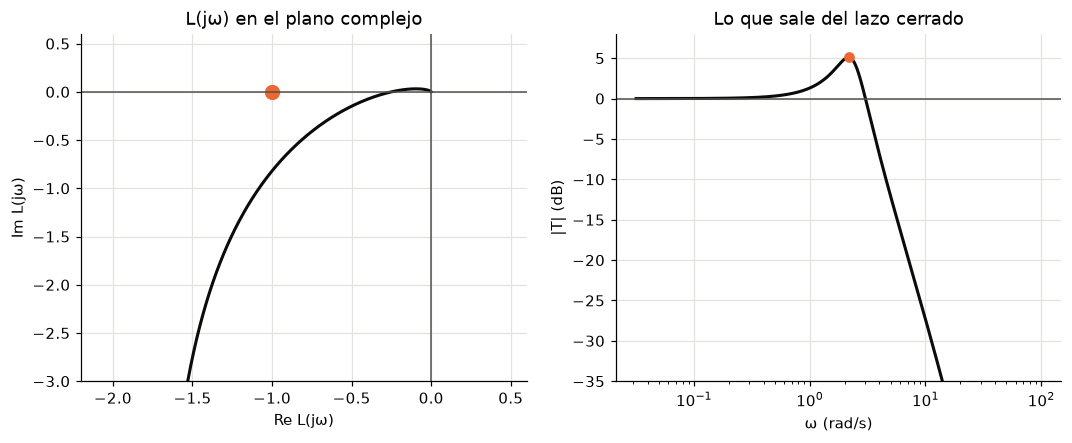

pico de |T| = 5.10 dB en ω = 2.16 rad/s


In [6]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 4.1))
a.plot(z.real, z.imag, color=TINTA, lw=2); a.plot(-1, 0, "o", color=NARANJA, ms=9)
a.axhline(0, color=GRIS, lw=1); a.axvline(0, color=GRIS, lw=1); a.set_xlim(-2.2, 0.6); a.set_ylim(-3, 0.6)
a.set_xlabel("Re L(jω)"); a.set_ylabel("Im L(jω)"); a.set_title("L(jω) en el plano complejo")
b.semilogx(w, db(T), color=TINTA, lw=2); b.axhline(0, color=GRIS, lw=1); b.set_ylim(-35, 8)
b.set_xlabel("ω (rad/s)"); b.set_ylabel("|T| (dB)"); b.set_title("Lo que sale del lazo cerrado")
i = np.argmax(db(T)); b.plot(w[i], db(T)[i], "o", color=NARANJA)
plt.show()
print(f"pico de |T| = {db(T)[i]:.2f} dB en ω = {w[i]:.2f} rad/s")

El pico de $|T|$ aparece justo donde $L$ pasa más cerca de $-1$. **Ese pico es lo que acotan las especificaciones de estabilidad en QFT** (Paso 8: $|T|\le W_s$).

## 5. Ejercicio del Paso 5

En cierta frecuencia $L=1\angle-135^\circ$.

1. $1+L$ en forma rectangular y polar.
2. $|T|$ en dB y $\angle T$.
3. ¿Está $L$ «cerca» de $-1$? Compara $|1+L|$ con $|L|$.

**Tu turno.**

In [7]:
L1 = np.exp(-1j * np.radians(135))
# 1) 1 + L1  (rectangular y polar)
# 2) T = L/(1+L): dB y fase
# 3) comparar |1+L| con |L|
# escribe aquí tu código

In [8]:
L1 = np.exp(-1j * np.radians(135))
print(f"1 + L = {(1+L1).real:.4f} {(1+L1).imag:+.4f}j  =  {abs(1+L1):.4f}∠{ang(1+L1):.2f}°")
Tt = T_de(L1)
print(f"|T| = {abs(Tt):.4f} = {db(Tt):.2f} dB (esperado 2.32 dB),  ∠T = {ang(Tt):.2f}°")
print(f"|1+L| = {abs(1+L1):.3f} < |L| = 1  ->  L está más cerca de -1 que del origen: T amplifica ({db(Tt):.2f} dB > 0)")
assert np.isclose(db(Tt), 2.32, atol=0.01)

1 + L = 0.2929 -0.7071j  =  0.7654∠-67.50°
|T| = 1.3066 = 2.32 dB (esperado 2.32 dB),  ∠T = -67.50°
|1+L| = 0.765 < |L| = 1  ->  L está más cerca de -1 que del origen: T amplifica (2.32 dB > 0)


## 6. Resumen

- $T=\dfrac{L}{1+L}$, $S=\dfrac{1}{1+L}$, $T+S=1$.
- $|1+L|$ = distancia de $L(j\omega)$ al punto $-1$; cerca ⇒ picos en $|T|$ y $|S|$.
- $|L|\gg1$: $T\approx1$; $|L|\ll1$: $T\approx L$; $|L|\approx1$ es la zona crítica.
- En lugar de leer picos en el plano complejo, el **Nichols chart** (Paso 6) pone $T$ directamente sobre un mapa (fase, dB).

**Siguiente:** Paso 6, el Nichols chart.